#TC2034 Modelación del Aprendizaje con Inteligencia Artificial
##Aprendizaje Supervisado
###Predicción de Depresión en Estudiantes
Steffany Mishell Lara Muy
A00838589





In [ ]:
# importar la biblioteca para análisis de datos
import numpy as np
# importar la biblioteca para graficación
import matplotlib.pyplot as plt
%matplotlib inline
# importar la biblioteca para manipulación y tratamiento de datos
import pandas as pd

## Lectura y preprocesamiento del conjunto de datos

In [ ]:
# leer el conjunto de datos a utilizar
datasetOriginal = pd.read_csv('Student Depression Dataset.csv')

df = datasetOriginal.copy()
# desplegar las primeras 5 líneas del dataframe
df.head()

# Categóricos: gender, city, profession, dietary habits, degree, suicidal thoughts, family history of mental illness.
# Continuos: age, academic pressure, cgpa, work pressure, study satisfaction, job satasfaction, work/study hours, depression.
# sleep duration es una combinación de tipos de datos numéricos y alfanuméricos.

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [ ]:
# determinar la cantidad de datos distintos en cada columna
df.nunique()

,0
id,27901
Gender,2
Age,34
City,52
Profession,14
Academic Pressure,6
Work Pressure,3
CGPA,332
Study Satisfaction,6
Job Satisfaction,5


In [ ]:


# Cambiaré los nombres de algunas columnas para que sea más fácil el manejo de datos.

df.rename(columns={"Academic Pressure":"AcademicPressure","Work Pressure":"WorkPressure",
                   "Study Satisfaction":"StudySatisfaction","Job Satisfaction":"JobSatisfaction",
                   "Sleep Duration":"SleepDuration","Dietary Habits":"DietaryHabits",
                   "Have you ever had suicidal thoughts ?":"SuicidalThoughts","Work/Study Hours":"WorkStudyHours",
                   "Financial Stress":"FinancialStress","Family History of Mental Illness":"FamilyHistory",}, inplace=True)
# estadísticas de los atributos numéricos
df.describe()

# Las muestras totales son 27901 y viene completo en todas las columnas.
# Survived es una característica categórica con valores de 0 o 1.
# Alrededor del 38% de las muestras sobrevivieron mientras que la tasa de real fue del 32% (1502 de 2224).
# La mayoría de los encuestados (> 75%) tienen depresión.
# El 25% no tiene depresión.
# EL 59% de los encuestados tiene depresión. La edad promedio es 25 años.
# El promedio está en una escala de 10 (CGPA) y la media es 7.66.
# El 75% de los estudiantes tienen presión académica (>4 en una escala de 5), pero no poseen en su mayoría presión laboral.
# Tienen una satisfacción promedio 2.94/5 en sus estudios y 0 en laboral, puede ser porque no trabajan o no están satisfechas.
# La mayoría estudia/trabaja entre 4 a 10 horas al día.
# Tienen un estrés financiero moderado 3.14/5

,id,Age,AcademicPressure,WorkPressure,CGPA,StudySatisfaction,JobSatisfaction,WorkStudyHours,FinancialStress,Depression
count,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27898.000000,27901.000000
mean,70442.149421,25.822300,3.141214,0.000430,7.656104,2.943837,0.000681,7.156984,3.139867,0.585499
std,40641.175216,4.905687,1.381465,0.043992,1.470707,1.361148,0.044394,3.707642,1.437347,0.492645
min,2.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,35039.000000,21.000000,2.000000,0.000000,6.290000,2.000000,0.000000,4.000000,2.000000,0.000000
50%,70684.000000,25.000000,3.000000,0.000000,7.770000,3.000000,0.000000,8.000000,3.000000,1.000000
75%,105818.000000,30.000000,4.000000,0.000000,8.920000,4.000000,0.000000,10.000000,4.000000,1.000000
max,140699.000000,59.000000,5.000000,5.000000,10.000000,5.000000,4.000000,12.000000,5.000000,1.000000


In [ ]:
# estadísticas de los atributos string (Object)
df.describe(include=['O'])


,Gender,City,Profession,SleepDuration,DietaryHabits,Degree,SuicidalThoughts,FamilyHistory
count,27901,27901,27901,27901,27901,27901,27901,27901
unique,2,52,14,5,4,28,2,2
top,Male,Kalyan,Student,Less than 5 hours,Unhealthy,Class 12,Yes,No
freq,15547,1570,27870,8310,10317,6080,17656,14398


In [ ]:
# Pese a ser categóricos pueden ser cambiados a binario las categorías género, suicidal thoughts y family history of mental illness porque las respuestas son
# si (1) o no (0)

df["SuicidalThoughts"] = df["SuicidalThoughts"].map({"Yes": 1, "No": 0})
df["Gender"]= df["Gender"].map({"Male":0,"Female":1})
df["FamilyHistory"] = df["FamilyHistory"].map({"Yes": 1, "No": 0})
df.head(5)

#Como sé que todos son alumnos y la única variación de profesión fue alguien que puso su carrera, eliminaré profession del df

df.drop("Profession", axis=1,inplace=True)
df.head(5)





,id,Gender,Age,City,AcademicPressure,WorkPressure,CGPA,StudySatisfaction,JobSatisfaction,SleepDuration,DietaryHabits,Degree,SuicidalThoughts,WorkStudyHours,FinancialStress,FamilyHistory,Depression
0,2,0,33.0,Visakhapatnam,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,1,3.0,1.0,0,1
1,8,1,24.0,Bangalore,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,0,3.0,2.0,1,0
2,26,0,31.0,Srinagar,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,0,9.0,1.0,1,0
3,30,1,28.0,Varanasi,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,1,4.0,5.0,1,1
4,32,1,25.0,Jaipur,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,1,1.0,1.0,0,0


In [ ]:
# Pese a ser categóricos quiero que los datos sean tomados en cuenta en scikit-learn, random forests y decision tree por lo que haré un label encoding con los datos
# categóricos.
# Cada guía de label y sus respectivos valores numéricos los guardaré en L_NombreVariable. Reemplazaré con los números los datos en el dataFrame
df["SleepDuration"] = df["SleepDuration"].map({"5-6 hours": 5.5, "Less than 5 hours": 2, "7-8 hours":7.5,"More than 8 hours":10,"Others":99})
df["DietaryHabits"],L_DietaryHabits = pd.factorize(df["DietaryHabits"])
df["Degree"],L_Degree = pd.factorize(df["Degree"])

# Verificar que coincida la cantidad de datos distintos (evidenciando una buena transición de categóricos a numéricos)
print("SleepDuration:", df["SleepDuration"].unique())
print("DietaryHabits:", df["DietaryHabits"].unique())
print("Degree:", df["Degree"].unique())
df.head(5)


SleepDuration: [ 5.5  2.   7.5 10.  99. ]
DietaryHabits: [0 1 2 3]
Degree: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27]


,id,Gender,Age,City,AcademicPressure,WorkPressure,CGPA,StudySatisfaction,JobSatisfaction,SleepDuration,DietaryHabits,Degree,SuicidalThoughts,WorkStudyHours,FinancialStress,FamilyHistory,Depression
0,2,0,33.0,Visakhapatnam,5.0,0.0,8.97,2.0,0.0,5.5,0,0,1,3.0,1.0,0,1
1,8,1,24.0,Bangalore,2.0,0.0,5.90,5.0,0.0,5.5,1,1,0,3.0,2.0,1,0
2,26,0,31.0,Srinagar,3.0,0.0,7.03,5.0,0.0,2.0,0,2,0,9.0,1.0,1,0
3,30,1,28.0,Varanasi,3.0,0.0,5.59,2.0,0.0,7.5,1,3,1,4.0,5.0,1,1
4,32,1,25.0,Jaipur,4.0,0.0,8.13,3.0,0.0,5.5,1,4,1,1.0,1.0,0,0


In [ ]:
# prompt: cuandos valores en df["SleepDuration"] son 99

# Assuming 'df' is your DataFrame as defined in the provided code.

# Count the number of times the value 99 appears in the "SleepDuration" column.
count_99 = df[df["SleepDuration"] == 99].shape[0]

print(f"Number of occurrences of 99 in 'SleepDuration': {count_99}")

#Como mi dataset es grande, eliminaré las 19 filas que tienen como sleep duration others (al cual le puse el valor centinela 99) porque no me
# brinda información relevante y sleepduration es importante en la depresión.

df.head(5)


# Eliminar las filas donde SleepDuration es igual a 99
df = df[df["SleepDuration"] != 99]


Number of occurrences of 99 in 'SleepDuration': 18


Valores NA en df:
 id                   0
Gender               0
Age                  0
City                 0
AcademicPressure     0
WorkPressure         0
CGPA                 0
StudySatisfaction    0
JobSatisfaction      0
SleepDuration        0
DietaryHabits        0
Degree               0
SuicidalThoughts     0
WorkStudyHours       0
FinancialStress      3
FamilyHistory        0
Depression           0
dtype: int64


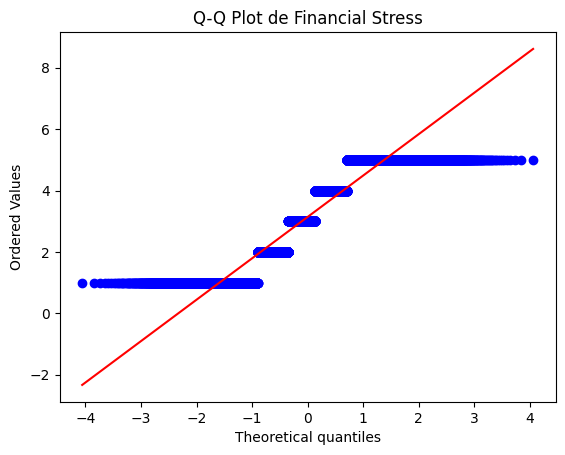

In [ ]:
# Revisar si hay NA
print("Valores NA en df:\n",df.isna().sum())

#revisaré si tienen a una normalidad en esa columna, en caso de que si reemplazaré los NA con la media

import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(df["FinancialStress"].dropna(), dist="norm", plot=plt)
plt.title("Q-Q Plot de Financial Stress")
plt.show()

# No es una distribución normal, como hay 3 NA y son 27k columnas preferí eliminar esas filas en lugar de rellenarlas con valores como la media
df = df.dropna(subset=["FinancialStress"])

#Suposiciones basadas en el análisis de datos
Llegamos a las siguientes suposiciones basados en el análisis de datos realizados hasta ahora. Podríamos validar más estos supuestos antes de tomar las acciones apropiadas.

###Correlacionando

1.   Queremos saber qué tan bien se correlaciona cada característica con padece depresión.
2.   Queremos hacer esto al principio de nuestro proyecto y coincidir con estas correlaciones rápidas con correlaciones modeladas más adelante en el proyecto.

###Completando

1. Las filas con NA en FinancialStress fueron eliminadas.

###Corrigiendo.

1. Profesión puede eliminarse del df porque todos son estudiantes.
2. Los datos categóricos nominales se les hizo un encode para que fueran numéricos ordinales: Sleep Duration, Degree, Dietary Habits.
3. Las categorías género, suicidal thoughts y family history of mental illness eran categóricas nominales con 2 opciones distintas por lo que se convirtió en binario (0 y 1).
4. Se eliminar 3 filas donde financialstrees era NA porque nuestro dataSet es grande.
5. Se eliminaron 19 filas donde sleephours era "others" dado que las categorías eran: menos de 5 horas, 5-6 horas, 7-8 horas y más de 8 horas, por tanto ese valor podría generar outliers que perjudiquen los modelos, más tomando en cuenta que los decision trees, random forest y sobre todo los suppor vector machine son sensibles a datos atípicos.

###Creando



###Clasificando

También podemos agregar a nuestras **suposiciones** en función de la descripción original del problema que:

1. Entre menor el CGPA más probabilidad de depresión.
2. (Sex = Male (0)) tenían más probabilidades de tener depresión.
3. Si los familiares tienen historial de enfermedades mentales serán máws propensos a tener depresión.


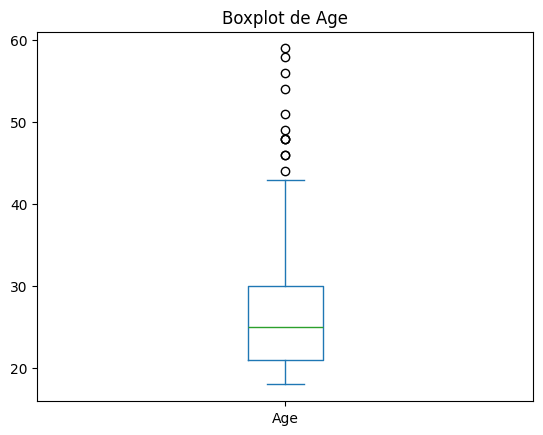

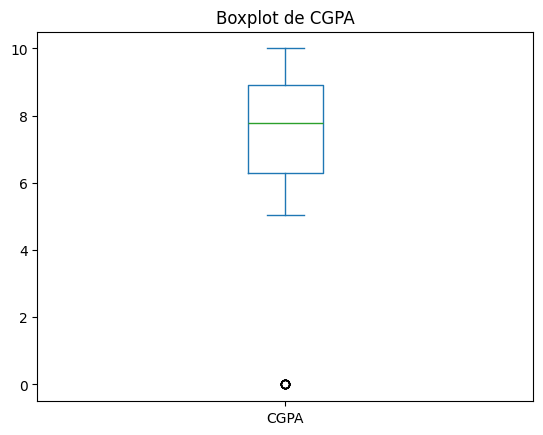

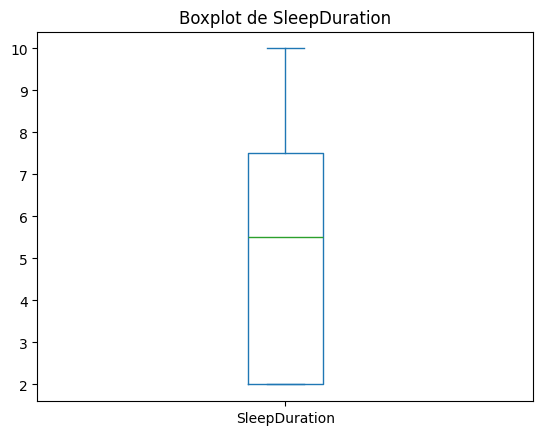

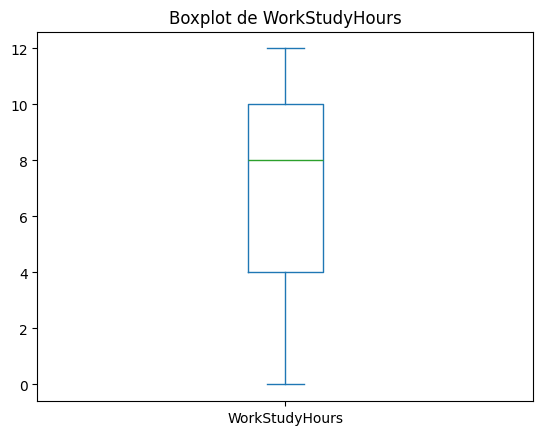

In [ ]:
# Mostraré gráficos para mostrar información relevante de los encuestados:

# Lista de columnas a graficar
columns = ['Age', 'CGPA', 'SleepDuration', 'WorkStudyHours']

for col in columns:
    plt.figure()  # Crea una nueva figura para cada gráfico
    df[col].plot(kind='box')
    plt.title(f"Boxplot de {col}")  # Agrega un título
    plt.show()  # Muestra el gráfico antes de pasar al siguiente


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27880 entries, 0 to 27900
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 27880 non-null  int64  
 1   Gender             27880 non-null  int64  
 2   Age                27880 non-null  float64
 3   City               27880 non-null  object 
 4   AcademicPressure   27880 non-null  float64
 5   WorkPressure       27880 non-null  float64
 6   CGPA               27880 non-null  float64
 7   StudySatisfaction  27880 non-null  float64
 8   JobSatisfaction    27880 non-null  float64
 9   SleepDuration      27880 non-null  float64
 10  DietaryHabits      27880 non-null  int64  
 11  Degree             27880 non-null  int64  
 12  SuicidalThoughts   27880 non-null  int64  
 13  WorkStudyHours     27880 non-null  float64
 14  FinancialStress    27880 non-null  float64
 15  FamilyHistory      27880 non-null  int64  
 16  Depression         27880 no

In [ ]:
# Normaliza los datos utilizando el escalador de datos para el svm

df3=df.copy()
df3 = df3.drop(columns=["City"])

from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

dataScaler = RobustScaler()
scaler = dataScaler.fit(df3)
dataScaled = scaler.transform(df3)

# muestra el arreglo resultante
dataScaled

array([[-0.99889436,  0.        ,  0.88888889, ..., -1.        ,
         0.        ,  0.        ],
       [-0.99880958,  1.        , -0.11111111, ..., -0.5       ,
         1.        , -1.        ],
       [-0.99855525,  0.        ,  0.66666667, ..., -1.        ,
         1.        , -1.        ],
       ...,
       [ 0.98896122,  0.        ,  0.66666667, ..., -0.5       ,
         0.        , -1.        ],
       [ 0.98897535,  1.        , -0.77777778, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.98910252,  0.        ,  0.22222222, ...,  0.        ,
         1.        ,  0.        ]])

In [ ]:
# crea un dataframe con los datos normalizados
data = pd.DataFrame(dataScaled)
data.columns = df3.columns

# muestra las primeras 5 líneas del dataframe resultante
data.head()

,id,Gender,Age,AcademicPressure,WorkPressure,CGPA,StudySatisfaction,JobSatisfaction,SleepDuration,DietaryHabits,Degree,SuicidalThoughts,WorkStudyHours,FinancialStress,FamilyHistory,Depression
0,-0.998894,0.0,0.888889,1.0,0.0,0.456274,-0.5,0.0,0.000000,-0.5,-0.9,0.0,-0.833333,-1.0,0.0,0.0
1,-0.998810,1.0,-0.111111,-0.5,0.0,-0.711027,1.0,0.0,0.000000,0.0,-0.8,-1.0,-0.833333,-0.5,1.0,-1.0
2,-0.998555,0.0,0.666667,0.0,0.0,-0.281369,1.0,0.0,-0.636364,-0.5,-0.7,-1.0,0.166667,-1.0,1.0,-1.0
3,-0.998499,1.0,0.333333,0.0,0.0,-0.828897,-0.5,0.0,0.363636,0.0,-0.6,0.0,-0.666667,1.0,1.0,0.0
4,-0.998470,1.0,0.000000,0.5,0.0,0.136882,0.0,0.0,0.000000,0.0,-0.5,0.0,-1.166667,-1.0,0.0,-1.0


In [ ]:
# muestra la información condensada del dataframe
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27880 entries, 0 to 27879
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 27880 non-null  float64
 1   Gender             27880 non-null  float64
 2   Age                27880 non-null  float64
 3   AcademicPressure   27880 non-null  float64
 4   WorkPressure       27880 non-null  float64
 5   CGPA               27880 non-null  float64
 6   StudySatisfaction  27880 non-null  float64
 7   JobSatisfaction    27880 non-null  float64
 8   SleepDuration      27880 non-null  float64
 9   DietaryHabits      27880 non-null  float64
 10  Degree             27880 non-null  float64
 11  SuicidalThoughts   27880 non-null  float64
 12  WorkStudyHours     27880 non-null  float64
 13  FinancialStress    27880 non-null  float64
 14  FamilyHistory      27880 non-null  float64
 15  Depression         27880 non-null  float64
dtypes: float64(16)
memory 

## Creación de conjuntos de entrenamiento y prueba

In [ ]:
# crea los conjuntos de entrenamiento (80%) y prueba (20%)
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(data, test_size=0.2, random_state=123)

X_train, y_train = train_df.drop(columns=["Depression"], axis=1), train_df["Depression"]
X_test, y_test = test_df.drop(columns=["Depression"], axis=1), test_df["Depression"]

# muestra la forma de los distintos conjuntos de datos obtenidos
print("Datos de entrenamiento=", X_train.shape, y_train.shape)
print("Datos de prueba=", X_test.shape, y_test.shape)

Datos de entrenamiento= (22304, 15) (22304,)
Datos de prueba= (5576, 15) (5576,)


##Creación de Modelos de Aprendizaje

### Regresión Logística

In [ ]:
# utiliza validación cruzada de 10 folds para evaluar el desempeño promedio
# de una Regresión Logística con C = 0.001 y solver = 'newton-cg'
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression

lrc = LogisticRegression(C=0.001, solver='newton-cg')
scores = pd.DataFrame(cross_validate(lrc, X_train, y_train, cv=10, return_train_score=True))

# despliega los score promedio de entrenamiento y validación, así como los
# resultados obtenidos para cada uno de los 10 folds
print("score promedio de entrenamiento = ", scores['train_score'].mean())
print("score promedio de validación = ", scores['test_score'].mean())
scores
#vemos que el test score es similar al train score por lo que el modelo generaliza bien.

score promedio de entrenamiento =  0.8423750642525014
score promedio de validación =  0.8418671873900783


,fit_time,score_time,test_score,train_score
0,0.099319,0.003426,0.847154,0.842276
1,0.050621,0.003283,0.840879,0.842326
2,0.048967,0.003268,0.842671,0.842276
3,0.047838,0.003207,0.831017,0.843521
4,0.048889,0.003643,0.832287,0.843180
5,0.047891,0.003217,0.836323,0.843031
6,0.047631,0.003351,0.845740,0.842234
7,0.047299,0.003202,0.846637,0.841636
8,0.047150,0.003190,0.843946,0.841736
9,0.048361,0.003225,0.852018,0.841536


In [ ]:
# determina, entre algunas alternativas, los mejores valores de hiperparámetros
# para construir un bosque aleatorio para el problema
from sklearn.model_selection import RandomizedSearchCV
import warnings
warnings.filterwarnings("ignore")

parameters = {'C': np.logspace(-4, 4, 50),
              'solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']}
lrc_rand = RandomizedSearchCV(LogisticRegression(random_state=1), n_iter=48,
                              param_distributions = parameters,
                              return_train_score=True)
lrc_rand.fit(X_train, y_train)

# despliega los mejores hiperparámetros encontrados
print("Mejores hiperparámetros\n", lrc_rand.best_params_)

Mejores hiperparámetros
 {'solver': 'saga', 'C': 0.013257113655901081}


In [ ]:
# quédate con la Regresión Logística con los mejores hiperparámetros encontrados y
# despliega su score con los datos del conjunto de prueba.
lrc_model = lrc_rand.best_estimator_
lrc_model.score(X_test, y_test)

0.8473816355810617

              precision    recall  f1-score   support

        -1.0       0.84      0.79      0.81      2308
         0.0       0.86      0.89      0.87      3268

    accuracy                           0.85      5576
   macro avg       0.85      0.84      0.84      5576
weighted avg       0.85      0.85      0.85      5576



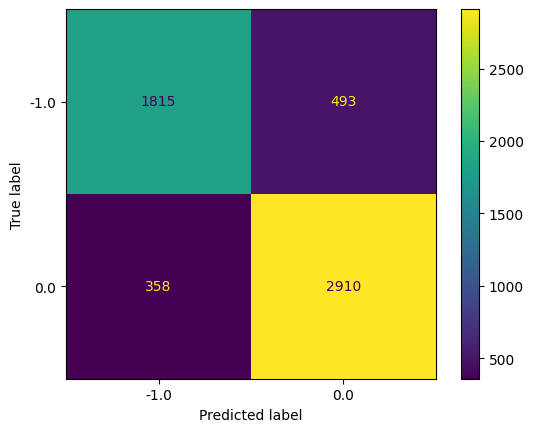

In [ ]:
# calcula las matriz de confusión y las métricas de evaluación con el conjunto
# de prueba para la mejor Regresión Logística
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

ConfusionMatrixDisplay.from_estimator(lrc_model, X_test, y_test)
print(classification_report(y_test, lrc_model.predict(X_test)))

### Bosque Aleatorio

In [ ]:
# utiliza validación cruzada de 10 folds para evaluar el desempeño promedio
# de bosques aleatorios de 10 árboles con una profundidad máxima de 3
from sklearn.ensemble import RandomForestClassifier

rfcInicial_model = RandomForestClassifier(n_estimators=10, max_depth=3)
scores = pd.DataFrame(cross_validate(rfcInicial_model, X_train, y_train, cv=10, return_train_score=True))

# despliega los score promedio de entrenamiento y validación, así como los
# resultados obtenidos para cada uno de los 10 folds
print("score promedio de entrenamiento = ", scores['train_score'].mean())
print("score promedio de validación = ", scores['test_score'].mean())
scores

score promedio de entrenamiento =  0.8114886023690128
score promedio de validación =  0.8106181145015305


,fit_time,score_time,test_score,train_score
0,0.127164,0.005733,0.815329,0.814676
1,0.124519,0.005598,0.810399,0.815772
2,0.115099,0.007505,0.796056,0.794749
3,0.126956,0.006274,0.794263,0.796842
4,0.116935,0.005824,0.809417,0.818621
5,0.115112,0.006211,0.808969,0.819069
6,0.118773,0.005325,0.789686,0.793962
7,0.124055,0.007607,0.829148,0.824549
8,0.133441,0.006577,0.812108,0.812743
9,0.135965,0.008682,0.840807,0.823902


In [ ]:
# determina, entre algunas alternativas, los mejores valores de hiperparámetros
# para construir un bosque aleatorio para el problema
from sklearn.model_selection import GridSearchCV

parameters = {'max_depth': [2, 3, 5, 7],
              'max_features': ['sqrt', 'log2', None],
              'n_estimators': [10, 30, 60, 100]}
rfc_grid = GridSearchCV(RandomForestClassifier(random_state=1), param_grid = parameters,
                        return_train_score=True)
rfc_grid.fit(X_train, y_train)

# despliega los mejores hiperparámetros encontrados
print("Mejores hiperparámetros\n",rfc_grid.best_params_)

Mejores hiperparámetros
 {'max_depth': 7, 'max_features': None, 'n_estimators': 60}


In [ ]:
# quédate con el Bosque Aleatorio con los mejores hiperparámetros encontrados y
# despliega su score con los datos del conjunto de prueba.
rfc_model = rfc_grid.best_estimator_
rfc_model.score(X_test, y_test)

0.841284074605452

              precision    recall  f1-score   support

        -1.0       0.82      0.79      0.80      2308
         0.0       0.85      0.88      0.87      3268

    accuracy                           0.84      5576
   macro avg       0.84      0.83      0.84      5576
weighted avg       0.84      0.84      0.84      5576



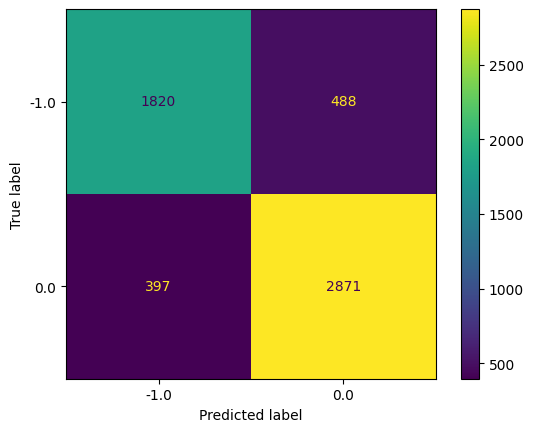

In [ ]:
# calcula las matriz de confusión y las métricas de evaluación con el conjunto
# de prueba para el mejor Bosque Aleatorio
ConfusionMatrixDisplay.from_estimator(rfc_model, X_test, y_test)
print(classification_report(y_test, rfc_model.predict(X_test)))

###Máquina de Vectores de Soporte

In [ ]:
# utiliza validación cruzada de 10 folds para evaluar el desempeño promedio
# de una Máquina de Vectores de Soporte con un parámetro de regularización de
# 0.01 y un kernel polinomial
from sklearn.model_selection import cross_validate
from sklearn.svm import SVC

svmc_model = SVC(C=0.01, kernel="poly")

scores = pd.DataFrame(cross_validate(svmc_model, X_train, y_train, cv=10, return_train_score=True))

# despliega los score promedio de entrenamiento y validación, así como los
# resultados obtenidos para cada uno de los 10 folds
print("score promedio de entrenamiento = ", scores['train_score'].mean())
print("score promedio de validación = ", scores['test_score'].mean())
scores

score promedio de entrenamiento =  0.8204059037755194
score promedio de validación =  0.8182384982904969


,fit_time,score_time,test_score,train_score
0,12.519386,1.208834,0.823398,0.819758
1,12.972452,0.889402,0.818019,0.820904
2,12.933122,0.915020,0.822053,0.820057
3,13.290136,0.883629,0.818019,0.820406
4,12.781460,0.883182,0.800897,0.821012
5,12.967833,1.009157,0.813004,0.821112
6,12.892570,0.901654,0.815247,0.819767
7,13.129169,0.916763,0.824215,0.819866
8,12.960647,0.892743,0.818834,0.821809
9,12.851872,1.349853,0.828700,0.819368


In [ ]:
# determina, entre algunas alternativas, los mejores valores de hiperparámetros
# para construir una Máquina de Vectores de Soporte para el problema
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
import numpy as np

parameters = {'C': np.logspace(-2, 2, 4),
              'kernel': ['linear', 'rbf', 'sigmoid']}

svmc_grid = GridSearchCV(
    SVC(random_state=1),
    param_grid=parameters,
    cv=3,  # Reducir la validación cruzada a 3 folds en vez de 5 o 10
    verbose=1,  # Mostrar progreso en la terminal
    n_jobs=-1, # Usa todos los núcleos disponibles para paralelizar la búsqueda # Usa todos los núcleos disponibles)
    return_train_score=True
)
svmc_grid.fit(X_train, y_train)
print("Mejores hiperparámetros\n",svmc_grid.best_params_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Mejores hiperparámetros
 {'C': 0.01, 'kernel': 'linear'}


In [ ]:
# quédate con la Máquina de Vectores de Soporte con los mejores hiperparámetros
# encontrados y despliega su score con los datos del conjunto de prueba.
svmc_model = svmc_grid.best_estimator_
svmc_model.score(X_test, y_test)

0.8468436154949784

              precision    recall  f1-score   support

        -1.0       0.83      0.79      0.81      2308
         0.0       0.85      0.89      0.87      3268

    accuracy                           0.85      5576
   macro avg       0.84      0.84      0.84      5576
weighted avg       0.85      0.85      0.85      5576



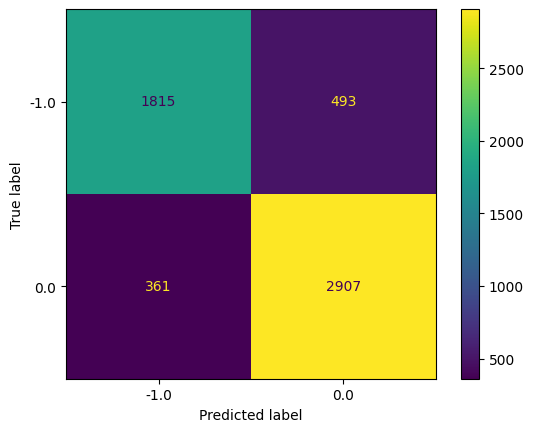

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
# calcula las matriz de confusión y las métricas de evaluación con el conjunto
# de prueba para el mejor Bosque Aleatorio
ConfusionMatrixDisplay.from_estimator(svmc_model, X_test, y_test)
print(classification_report(y_test, svmc_model.predict(X_test)))

## Mejor Modelo de Aprendizaje mediante Curva ROC

<Figure size 640x480 with 0 Axes>

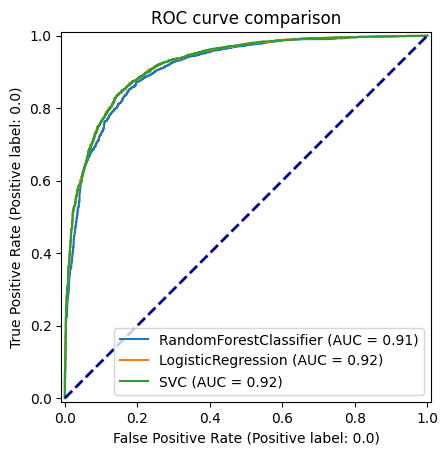

In [ ]:
# calcular y mostrar las curvas ROC de cada modelo de aprendizaje
# y sus métricas de área bajo la curva (AUC)
from sklearn.metrics import RocCurveDisplay

plt.figure()
lw = 2
disp = RocCurveDisplay.from_estimator(rfc_model, X_test, y_test)
RocCurveDisplay.from_estimator(lrc_model, X_test, y_test, ax=disp.ax_)
RocCurveDisplay.from_estimator(svmc_model, X_test, y_test, ax=disp.ax_)
plt.plot([0, 1], [0, 1], color="navy", lw=lw, linestyle="--")
plt.title("ROC curve comparison")
plt.legend(loc="lower right")
plt.show()

In [ ]:
print(y_train.unique())
print(y_test.unique())
print(y_train.value_counts())
print(y_test.value_counts())
print(train_df["Depression"].unique())


[-1.  0.]
[ 0. -1.]
Depression
 0.0    13058
-1.0     9246
Name: count, dtype: int64
Depression
 0.0    3268
-1.0    2308
Name: count, dtype: int64
[-1.  0.]


##**Conclusión**: Los mejores modelos de aprendizaje supervisado fueron Logistic Regression y Support Vector Classification (SVC) ambos con un AUC de 0.92, pese a eso la Random Forest Classification fue de 0.91. Por tanto todos los modelos son excelentes para la clasificación.

Algo que aprendí durante la lección de regresión logística fue lo esencial que es elegir un buen data set, que tuviera múltiples características que permitieran la predicción de determinado estado. Por tanto, esta vez busqué una temática en Kaggle que fue salud mental y elegí el dataset que tuviera más filas, múltiples caracterísitcas realmente relevantes y también determinara "algo" que en este caso fue que un estudiante padeciera depresión.

Analizando los datos me di cuenta que todos eran relevantes, a excepción de la columna de profesión dado que todos eran alumnos por lo que la eliminé. La ciudad tampoco la tomé como referencia.

Posteriormente busqué de cada categoría cuantas de las opciones de cada columna eran "únicas", así notando que existían varias respuestas de sí y no así que lo convertí a una respuesta binaria 1 (si) y 0 (no). Noté que existían datos categóricos nominales y los convertí todos a numéricos discretos para que las librerías pudieran tomar dicha característica en cuenta durante el entrenamiento.

Algo que noté y me asustó de sobremanera al tener el ROC, fue ver que la clasificación estaba entre 0 y -1 en lugar de 0 y 1. La razón es que al normalizar los datos RobustScaler centra los datos en la mediana, y como Depression es binaria (0 y 1), al transformarla con RobustScaler puede convertir 1 en -1 y dejar 0 igual.

Ahora si, hablando de métricas (precisión, recall, f1-score, accuracy). El modelo de regresión logística [RLC] con 0.86 fue mejor para detectar precisión en quienes no tienen depresión. Por otra parte todos tienen la misma efectividad 0.79 en recall de personas que sí tienen depresión. Adicionalmente, empataron con 0.87 en f1-score para personas sin depresión. En general, el porcentaje de predicciones correctas acorde al reporte de clasificación de sklearn es de 0.85 para RLC y Support Vector Classification [SVC] y de 0.84 para Random Forest Classification [RFC]. Pese a eso en el AUC tienen 0-.92 tanto RLC como SVC y 0.91 RFC.

En general, podría decir fue grato comprender a hacer predicciones con base a datos reales dado que se puede inferir el comportamiento o estado de una persona acorde a ciertas características. Además, aprendí que el tiempo de entrenamiento del modelo depende mucho del computador pero también de la programación, como tardó mucho tiempo aprendí del comando n_jobs=-1 para usar todos los núcleos disponibles en la computadora. Adicionalmente, que puedes poner múltiples parámetros y con GridSearchCV elegir hacer comparaciones de eficiencia y posteriormente elegir los mejores parámetros. Considero es esencial para hacer predicciones efectivas, lo único es que conlleva un costo computacional mayor. Con respecto a mi computadora MacOS tomó mucho más tiempo que la de un amigo con computadora gamer windows con mi código, comparamos el tiempo de este programa y con él tardó 25 minutos en total mientras yo estuve toda la tarde esperando a que cargara. Como aprendizaje también llevo hacer estas tareas con más antelación para prevenir problemas con la fecha de entrega y el tiempo de entrenamiento del modelo. Si hubiese tenido más tiempo en mi reporte estaría el decision tree para hacer comparaciones dado que en mi tarea anterior el DT fue más eficiente que RF, me queda la duda de si hubiese sido mejor la efectividad que la de los otros modelos.

